<a href="https://colab.research.google.com/github/joshbaron42/Steam-Games-392/blob/josh/BUS392_Q1_Q4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Question 1
##Step 1: Load the cleaned data


In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/joshbaron42/Steam-Games-392/cleaned-data/steam_clean.csv"
gamesData = pd.read_csv(url, parse_dates=["release_date"])
print(gamesData.shape)

(150559, 15)


## Step 2: Add review columns
We added two columns: `total_reviews` and `positive_pct` (the percent of reviews that are positive)

In [3]:
gamesData["total_reviews"] = gamesData["positive"] + gamesData["negative"]
gamesData["positive_pct"] = gamesData["positive"] / gamesData["total_reviews"] * 100
gamesData[["name", "positive", "negative", "total_reviews", "positive_pct"]].head()

,name,positive,negative,total_reviews,positive_pct
0,EllrLand,38,28,66,57.575758
1,MiNNaDe Counter Fight,12,6,18,66.666667
2,BattleParty,17,9,26,65.384615
3,BookConverter,0,0,0,NaN
4,SAMURAI SHODOWN,0,0,0,NaN


## Step 3: How we define popularity
We looked at three ways to measure popularity:
- **Estimated owners** (`owners_midpoint`): how many people own the game. This is only a rough range.
- **Total reviews** (`total_reviews`): how many people reviewed the game. This is an exact count.
- **Recommendations**: how many people recommended the game. Many games are blank here.


## Step 4: Free vs. paid games
We compared free and paid games on each popularity measure. We left out the 1,374
"unavailable" games because they are no longer for sale. The % positive average only
uses games with 10 or more reviews, since a percent from 1 or 2 reviews isn't reliable.

In [4]:
avg_reviews = {}

for status in ["free", "paid"]:
    group = gamesData[gamesData["price_status"] == status]   # only free games, then only paid games
    reviewed = group[group["total_reviews"] >= 10]           # games with 10+ reviews
    print(status)
    print("  Number of games:", group["app_id"].count())
    print("  Average owners:", round(group["owners_midpoint"].mean()))
    print("  Average total reviews:", round(group["total_reviews"].mean()))
    print("  Average recommendations:", round(group["recommendations"].mean()))
    print("  Average % positive (10+ reviews):", round(reviewed["positive_pct"].mean(), 1))
    avg_reviews[status] = group["total_reviews"].mean()     # save for the chart

free
  Number of games: 28690
  Average owners: 195138
  Average total reviews: 1191
  Average recommendations: 736
  Average % positive (10+ reviews): 76.2
paid
  Number of games: 120495
  Average owners: 67205
  Average total reviews: 903
  Average recommendations: 1380
  Average % positive (10+ reviews): 77.5


**What we found:** Free games are more popular. They have about 3 times as many owners (195,138 vs. 67,205) and more reviews (1,191 vs. 903). Paid games get more recommendations (1,380 vs. 736), so the measures don't fully agree. Players like free and paid games about the same: 76.2% vs. 77.5% positive reviews.

## Step 5: Most popular games
We sorted all games by total reviews to find the 10 most popular.

In [5]:
top10 = gamesData.sort_values("total_reviews", ascending=False).head(10)   # biggest first, keep 10
top10[["name", "price_status", "owners_midpoint", "total_reviews", "positive_pct"]]

,name,price_status,owners_midpoint,total_reviews,positive_pct
67916,Counter-Strike 2,free,150000000.0,8815087,86.693234
114847,PUBG: BATTLEGROUNDS,free,150000000.0,2557944,59.440590
67913,Dota 2,free,150000000.0,2498969,81.519339
55442,Grand Theft Auto V Legacy,unavailable,75000000.0,1990556,87.411758
56386,Terraria,paid,35000000.0,1409473,97.481754
51387,Tom Clancy's Rainbow Six Siege,free,35000000.0,1398584,83.860104
54292,Rust,paid,35000000.0,1227784,87.241323
67910,Team Fortress 2,free,75000000.0,1161472,89.908668
68020,Garry's Mod,paid,35000000.0,1159707,96.795656
46434,Black Myth: Wukong,paid,75000000.0,1150098,96.663067


**What we found:** 5 of the top 10 games are free, even though only about 1 in 5 games
on Steam is free. Counter-Strike 2 is far ahead with 8.8 million reviews, more than 3 times
the next game. Most of the top 10 are online multiplayer games.

## Step 6: Chart
A bar chart comparing the average number of reviews for free and paid games.

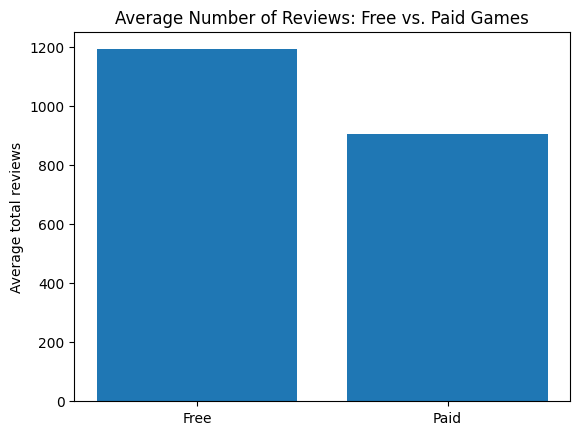

In [6]:
import matplotlib.pyplot as plt

plt.bar(["Free", "Paid"], [avg_reviews["free"], avg_reviews["paid"]])
plt.title("Average Number of Reviews: Free vs. Paid Games")
plt.ylabel("Average total reviews")
plt.savefig("q1_free_vs_paid.png")   # saves the chart so you can download it for the report
plt.show()

# Question 4

## Step 7: Pick games with complete data
To compare these measures fairly, every game needs a value for all of them. We kept only
games with playtime above 0 (0 means no data), a recommendations count, and an owners
estimate. That leaves 9,139 games.

In [7]:
q4 = gamesData[gamesData["average_playtime_forever"] > 0]
q4 = q4.dropna(subset=["recommendations", "owners_midpoint"])
print("Games used:", len(q4))

Games used: 9139


## Step 8: Correlation table
A correlation shows how closely two measures move together. 1 means they rise together
perfectly, 0 means no relationship.

In [8]:
columns = ["positive", "negative", "recommendations", "average_playtime_forever", "owners_midpoint"]
corr_table = q4[columns].corr()
corr_table.round(2)

,positive,negative,recommendations,average_playtime_forever,owners_midpoint
positive,1.00,0.53,0.93,0.03,0.73
negative,0.53,1.00,0.57,0.03,0.64
recommendations,0.93,0.57,1.00,0.03,0.70
average_playtime_forever,0.03,0.03,0.03,1.00,0.03
owners_midpoint,0.73,0.64,0.70,0.03,1.00


**What we found:**
- Positive reviews and recommendations agree almost perfectly (0.93). Games that get
  good reviews also get recommended.
- Reviews and ownership agree fairly strongly (0.73 for positive reviews). Games with more
  owners get more reviews. Negative reviews also rise with ownership (0.64), because popular
  games get more reviews of every kind.
- Playtime does not agree with any of the others (0.03). Games with lots of reviews or owners
  don't have higher average playtime. A few games with extremely high playtime numbers
  also pull this result down.

## Step 9: Chart
A bar chart showing how strongly positive reviews line up with each of the other measures.

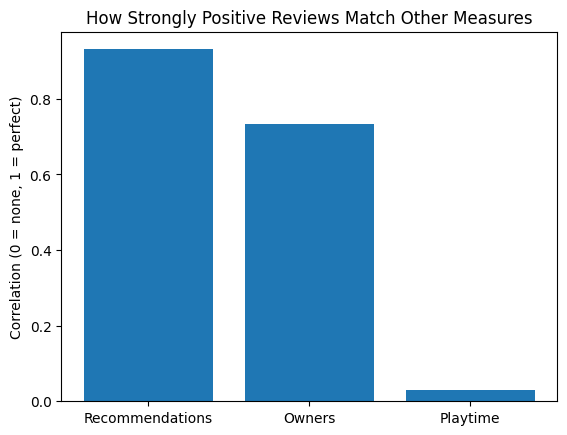

In [9]:
plt.bar(["Recommendations", "Owners", "Playtime"],
        [corr_table["positive"]["recommendations"],
         corr_table["positive"]["owners_midpoint"],
         corr_table["positive"]["average_playtime_forever"]])
plt.title("How Strongly Positive Reviews Match Other Measures")
plt.ylabel("Correlation (0 = none, 1 = perfect)")
plt.savefig("q4_correlation.png")
plt.show()